# Task 1: Anti-Cheat Pre-Filter
CPE342 Karena Thailand Player Intelligence. Binary classification, target `is_cheater`, metric $F_2$ (positive class: cheater).

This notebook is the Task 1 slice of `CPE342_Master_Pipeline.ipynb`: the same cells, the same shared code in `src/` and the same cached artefacts in `outputs/`, so both produce identical predictions. It ends by writing `outputs/submission_parts/task1.csv`; `python scripts/make_submission.py` joins the five parts into `submission.csv`.

**Rules followed.** Only the provided data are used; test rows are only ever predicted; every score and decision comes from 5-fold out-of-fold validation, and the final models are retrained on Train+Val combined; models are trained from scratch; no AutoML (Optuna for tuning); no leaderboard probing.

## Table of Contents
1. [Imports & Configuration](#1)
2. [Data Loading & Overview](#2)
3. [Exploratory Data Analysis](#3)
4. [Data Preparation & Feature Engineering](#4)
5. [Model Training & Evaluation](#5)
6. [Hyperparameter Tuning](#6)
7. [Stacking Ensemble (K-Fold) & Final Decision](#7)
8. [Feature Importance Analysis](#8)
9. [Submission](#9)
10. [Conclusion](#10)

<a id="1"></a>
# 1. Imports & Configuration

Global seeds, warning suppression, GPU discovery, and the exact competition metric, checked on toy inputs.

In [1]:
import os, sys, json, time, warnings, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "src").exists():          # notebook lives in taskN/; the shared code is one level up
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config as C
from src.config import SEED, N_FOLDS, FBETA_AVERAGE
from src.utils import seed_everything, quiet, reduce_mem_usage, timer, save_preds, load_preds, load_params
from src.metrics import (fbeta, f2, f3, macro_f1, nmae, optimize_threshold, threshold_curve,
                         optimize_class_weights, apply_class_weights)
from src.modeling import make_folds, run_cv, run_cv_sklearn
from src import viz
from src.viz import CAT, SEQ_CMAP, DIV_CMAP, MUTED, savefig

quiet()
seed_everything(SEED)
viz.set_theme()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

import torch, lightgbm, xgboost, catboost, sklearn, optuna
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | lightgbm {lightgbm.__version__} | "
      f"xgboost {xgboost.__version__} | catboost {catboost.__version__} | sklearn {sklearn.__version__} | optuna {optuna.__version__}")
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
AVG_NAME = "positive-class" if FBETA_AVERAGE == "binary" else "macro"
print(f"SEED={SEED}  N_FOLDS={N_FOLDS}  FBETA_AVERAGE={FBETA_AVERAGE!r}")

# Execution switches: heavy artifacts are cached in outputs/ and re-used unless forced.
RUN_OPTUNA = False          # True -> (re)run Optuna studies in-notebook (slow); False -> load stored studies
RUN_T4_TRAINING = False     # True -> launch the Task 4 GPU K-fold fine-tuning if fold caches are missing

python 3.14.6 | torch 2.14.1+cu130 | lightgbm 4.7.0 | xgboost 3.4.1 | catboost 1.2.10 | sklearn 1.9.1 | optuna 5.0.0
device: cuda | NVIDIA GeForce RTX 4070 Laptop GPU
SEED=42  N_FOLDS=5  FBETA_AVERAGE='binary'


In [2]:
# Sanity-check the metric implementations on toy inputs
y_t = np.array([1, 1, 1, 0, 0, 0, 0, 0])
y_p = np.array([1, 1, 0, 1, 0, 0, 0, 0])
P, R = 2 / 3, 2 / 3
assert abs(fbeta(y_t, y_p, 2, "binary") - 5 * P * R / (4 * P + R)) < 1e-12
assert abs(fbeta(y_t, y_p, 3, "binary") - 10 * P * R / (9 * P + R)) < 1e-12
assert abs(nmae([0, 10, 30], [5, 10, 20]) - 1 / (1 + 15 / 40)) < 1e-12
print("metric checks passed | macro-F2 toy:", round(f2(y_t, y_p, 'macro'), 4), "| binary-F2 toy:", round(f2(y_t, y_p, 'binary'), 4))

metric checks passed | macro-F2 toy: 0.7333 | binary-F2 toy: 0.6667


<a id="2"></a>
# 2. Data Loading & Overview

Row *i* of `test.csv` maps positionally to submission id `ANS{i:05d}` (25,889 rows).

**Data card.**
* **Task 1** has 31 behavioural / mechanical-skill features. 13,184 training rows carry no label and are dropped. Classes are 65% legitimate and 35% cheater.

In [3]:
from src import task1
t1_train, t1_test, t1_unlabeled = task1.load()
print(f"Task 1: dropped {t1_unlabeled:,} training rows whose label is missing")
reduce_mem_usage(t1_train, verbose=True)
display(pd.DataFrame({"train rows": [len(t1_train)], "test rows": [len(t1_test)], "features": [t1_test.shape[1] - 1],
                      "cheater share": [t1_train.is_cheater.mean()],
                      "missing (train / test)": [f"{t1_train.drop(columns='is_cheater').isna().mean().mean():.3f} / {t1_test.isna().mean().mean():.3f}"]}))

Task 1: dropped 13,184 training rows whose label is missing
memory 27.0 MB -> 15.7 MB (42% saved)


,train rows,test rows,features,cheater share,missing (train / test)
0,90816,25889,31,0.3493,0.116 / 0.077


<a id="3"></a>
# 3. Exploratory Data Analysis

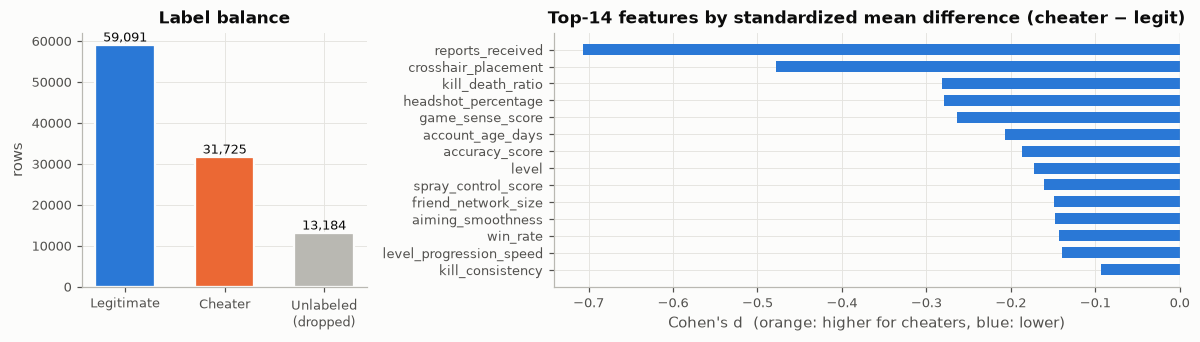

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1, 2.2]})
counts = pd.Series({"Legitimate": (t1_train.is_cheater == 0).sum(), "Cheater": (t1_train.is_cheater == 1).sum(), "Unlabeled\n(dropped)": t1_unlabeled})
axes[0].bar(counts.index, counts.values, color=[CAT[0], CAT[1], MUTED], width=0.6, **viz.bar_gap())
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8.5)
axes[0].set_title("Label balance"); axes[0].set_ylabel("rows")

# Univariate separability (|Cohen's d|) of every feature
num = t1_train.drop(columns=["player_id", "is_cheater"])
g = t1_train.groupby("is_cheater")
d = ((g[num.columns].mean().loc[1] - g[num.columns].mean().loc[0]) / num.std()).sort_values(key=np.abs)
axes[1].barh(d.index[-14:], d.values[-14:], color=[CAT[1] if v > 0 else CAT[0] for v in d.values[-14:]], height=0.65)
axes[1].axvline(0, color=MUTED, lw=0.8)
axes[1].set_title("Top-14 features by standardized mean difference (cheater − legit)")
axes[1].set_xlabel("Cohen's d  (orange: higher for cheaters, blue: lower)")
plt.tight_layout(); savefig(fig, "t1_eda_balance"); plt.show()

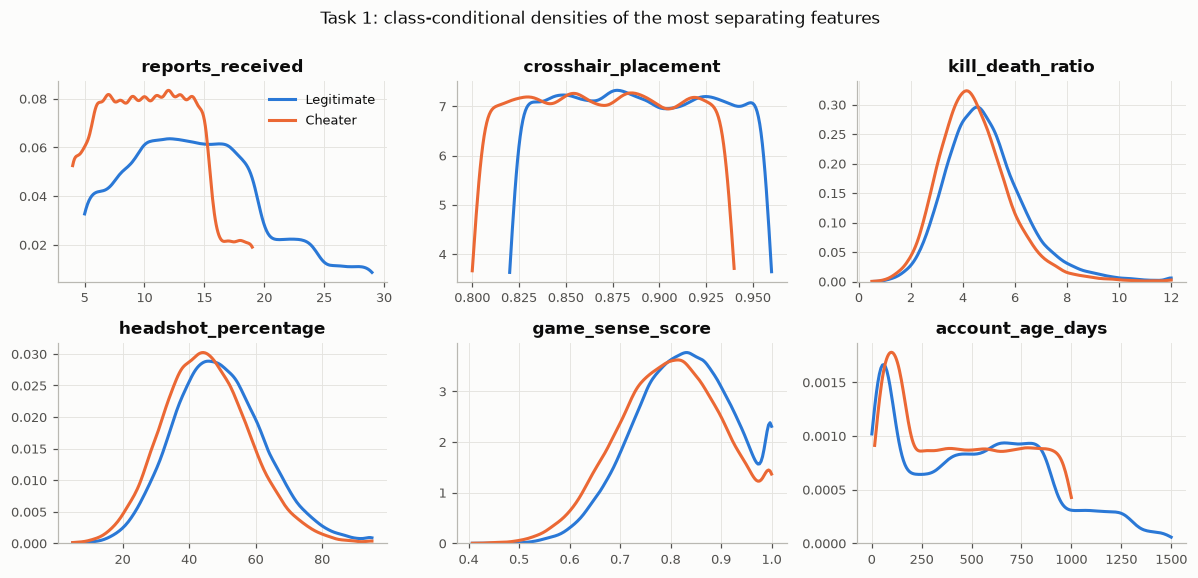

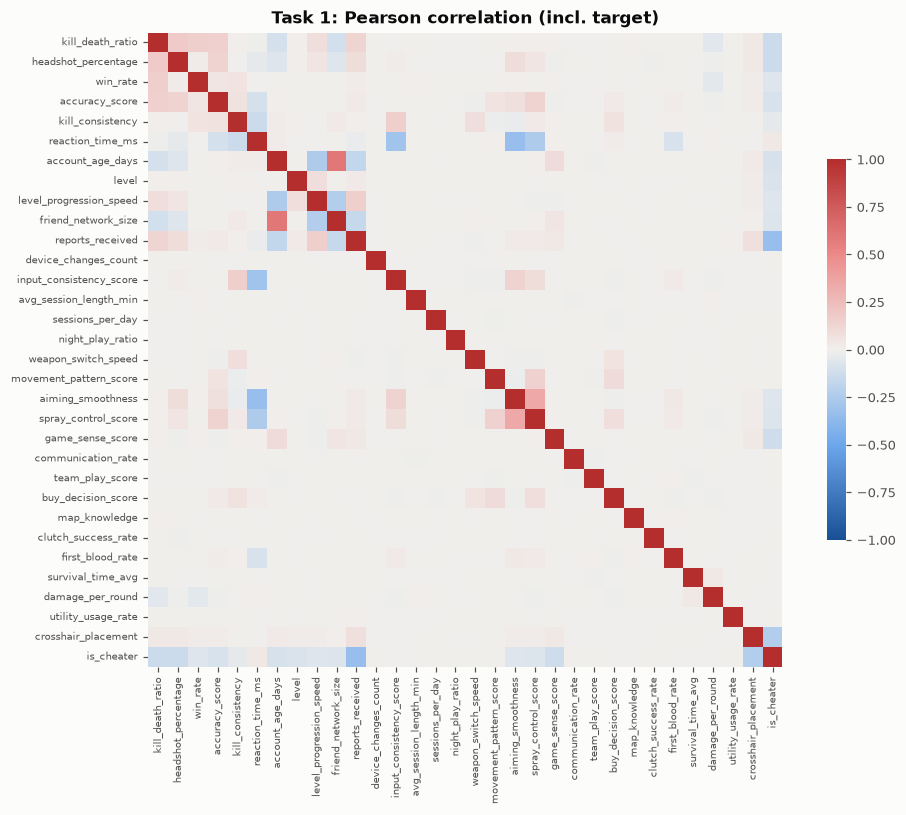

Strongest linear correlations with is_cheater:
reports_received      -0.3370
crosshair_placement   -0.2280
kill_death_ratio      -0.1340
headshot_percentage   -0.1330
game_sense_score      -0.1250
account_age_days      -0.0980
accuracy_score        -0.0890
level                 -0.0820


In [5]:
top6 = d.abs().sort_values(ascending=False).index[:6]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.2))
for ax, c in zip(axes.ravel(), top6):
    for k, lab in [(0, "Legitimate"), (1, "Cheater")]:
        sns.kdeplot(t1_train.loc[t1_train.is_cheater == k, c].dropna(), ax=ax, color=CAT[k], lw=2, label=lab, cut=0)
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("")
axes[0, 0].legend()
fig.suptitle("Task 1: class-conditional densities of the most separating features", y=1.0, fontsize=11)
plt.tight_layout(); savefig(fig, "t1_eda_kde"); plt.show()

fig, ax = plt.subplots(figsize=(9.5, 7.5))
corr = t1_train.drop(columns="player_id").corr()
sns.heatmap(corr, cmap=DIV_CMAP, vmin=-1, vmax=1, center=0, square=True, cbar_kws={"shrink": 0.6}, ax=ax,
            xticklabels=True, yticklabels=True)
ax.tick_params(labelsize=6.5); ax.set_title("Task 1: Pearson correlation (incl. target)")
plt.tight_layout(); savefig(fig, "t1_eda_corr"); plt.show()
print("Strongest linear correlations with is_cheater:")
print(corr["is_cheater"].drop("is_cheater").sort_values(key=np.abs, ascending=False).head(8).round(3).to_string())

**Findings.**
* **Every top feature is *lower* for cheaters** in this data: `reports_received` (d ≈ −0.7), `crosshair_placement`, K/D, headshot %, game sense, account age and level. This contradicts the textbook aimbot story of inflated K/D and headshot %, so the model must learn from the data rather than from domain priors. The counter-intuitive report sign matters too: heavily reported accounts are mostly *legitimate* players reported by frustrated opponents, which matches the brief's 70% false-positive complaint.
* **Class-specific supports.** Several features look near-uniform with *shifted* ranges per class. `reports_received` > 19, `account_age_days` > 1,000 and `crosshair_placement` > 0.94 occur only for legitimate players, and crosshair < 0.82 occurs only for cheaters. Trees capture these hard boundaries for free, and the residual difficulty lives in the overlap region.
* Pairwise correlations are weak and the separating signal is spread over many features. That is GBDT territory, with a realistic AUC ceiling near 0.89.

### Data-quality audit
Adversarial validation (train vs test), missing values vs target, impossible values, duplicates and collinearity, computed by `src/audit.py` on features only (see the master notebook §3.6).

In [6]:
from src import audit
with pd.option_context("display.max_colwidth", 120):
    display(pd.Series(audit.task_audit(t1_train, t1_test, "is_cheater"), name="Task 1").to_frame())

,Task 1
train-vs-test AUC: all features,0.9010
train-vs-test AUC: missing indicators only,0.9030
train-vs-test AUC: values (missing filled by train median),0.8910
largest value shift (KS),0.0100
missing rate train / test,0.120 / 0.080
informative missing columns (p < 0.001),0 of 31
physical issues,"win_rate: 2.9% of values exactly at the max (100), i.e. clipped; reaction_time_ms: 3.1% of values exactly at the min..."
duplicate test rows,0
duplicate train rows,0
test rows equal to a train row,0


**Audit findings.**
* **Task 1:** train and test are easy to tell apart (AUC ≈ 0.90), but only through *which* cells are missing. The indicators alone give the same AUC, while the observed values barely move (largest KS ≈ 0.01). Test rows miss the key columns far less often (`account_age_days` 14.5% → 0.6%, `avg_session_length_min` 22.9% → 1.6%) and a few others more often (`headshot_percentage` 2.7% → 14.1%). Missingness is unrelated to the label, so LightGBM keeps its native NaN handling. Missing-value indicators, median imputation and masking-robust training were all tested: none was better on at least 4 of 5 folds with a bootstrap interval above zero (`experiments/claude/FINDINGS.md`, round 10). Because test rows are more complete, the test $F_2$ should be *higher* than the OOF estimate: re-scoring the OOF predictions under the test's missing-value pattern gives 0.847 for LightGBM vs 0.835.
* **Missing values in Tasks 1–3:** no column is informative at p < 0.001. The cells are missing completely at random.
* **Impossible values:** none need cleaning. No percentage leaves [0, 100]. Several bounded scores are clipped at their limits (e.g. 8% of `aiming_smoothness` = 1 in Task 1), which trees handle. `account_age_days = 999` in Tasks 2/3 is not a sentinel: neighbouring values are just as frequent.
* **Duplicates / collinearity:** no duplicate rows within or across splits and no constant columns. The only collinear pairs are known structure: historical vs previous-month spending (Task 3, ratio 0.30–0.40) and the per-period location and skill-rating series (Task 5).

<a id="4"></a>
# 4. Data Preparation & Feature Engineering

**General policy.** GBDTs handle missing values natively, using a learned default direction per split, so tabular NaNs are left as-is for trees. All statistics used by the features (z-score means/SDs, frequencies) are computed on **training rows only** and then applied to test. Supervised encoders (target encoding) are fitted **inside each CV fold**.

## 4.1 Task 1: mechanical-anomaly ratios
*Domain hypothesis, tested in §5.1:* aimbots inflate *mechanical* skill without the matching *game sense*. We build ratios (`hs_per_accuracy`, `kd_per_reaction`, `accuracy_per_reaction`, `dmg_per_survival`), skill-vs-experience rates (`level_per_day`, `kd_per_level`, `skill_per_playtime`), report intensities (`reports_per_day`, `reports_per_friend`), and two composite z-indices: `mech_index`, `sense_index` and their gap `mech_minus_sense`.

Task 1 matrix: (90816, 49), test (25889, 49); engineered: ['hs_per_accuracy', 'kd_per_reaction', 'accuracy_per_reaction', 'hs_x_smooth', 'dmg_per_survival', 'kd_x_winrate', 'level_per_day', 'reports_per_day', 'reports_per_friend', 'device_changes_per_day', 'kd_per_level', 'daily_playtime', 'skill_per_playtime', 'input_x_smooth', 'mech_index', 'sense_index', 'mech_minus_sense', 'n_missing']


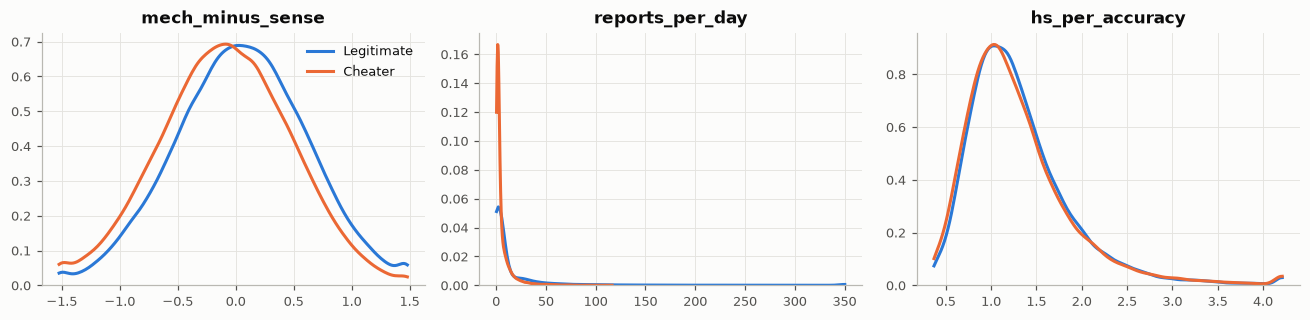

In [7]:
X1, y1, X1_test = task1.build(t1_train, t1_test)
new1 = [c for c in X1.columns if c not in t1_train.columns]
print(f"Task 1 matrix: {X1.shape}, test {X1_test.shape}; engineered: {new1}")
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, c in zip(axes, ["mech_minus_sense", "reports_per_day", "hs_per_accuracy"]):
    lo, hi = X1[c].quantile([0.005, 0.995])
    for k, lab in [(0, "Legitimate"), (1, "Cheater")]:
        sns.kdeplot(X1.loc[y1 == k, c].clip(lo, hi).dropna(), ax=ax, color=CAT[k], lw=2, label=lab, cut=0)
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("")
axes[0].legend(); plt.tight_layout(); savefig(fig, "t1_fe"); plt.show()

<a id="5"></a>
# 5. Model Training & Evaluation

**Validation protocol.** 5 folds (seed 42), `StratifiedKFold` on the label. Every model produces out-of-fold (OOF) predictions for every training row: they give honest scores, feed threshold/weight tuning and serve as stacking inputs. Test predictions average the 5 fold models. Results are cached in `outputs/preds/*.npz`; delete a file to retrain that model.

In [8]:
from sklearn.metrics import roc_auc_score, confusion_matrix, f1_score
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer

folds1 = make_folds(y1)
print("fold sizes:", [len(v) for _, v in folds1])

def cached(name, fn, force=False):
    # Return {'oof','test',...} arrays, training via fn() only when no cache exists.
    r = load_preds(name)
    if r is None or force:
        t0 = time.time()
        out = fn()
        r = {k: np.asarray(v) for k, v in out.items() if k in ("oof", "test", "p_oof", "mu_oof", "p_test", "mu_test", "sigma", "smear", "n_iter")}
        save_preds(name, **r)
        print(f"  trained {name} in {time.time() - t0:.0f}s")
    return r

BASE = {"learning_rate": 0.05}
summary = []   # running scoreboard

fold sizes: [18164, 18163, 18163, 18163, 18163]


### 5.1 Baseline and feature-engineering ablation (default LightGBM)

In [9]:
raw1 = [c for c in t1_train.columns if c not in ("player_id", "is_cheater")]
b = {}
b["T1 raw"] = cached("t1_base_raw", lambda: run_cv("lgb", "binary", BASE, X1[raw1], y1, X1_test[raw1], folds1, name="T1 raw"))
b["T1 FE"] = cached("t1_base_fe", lambda: run_cv("lgb", "binary", BASE, X1, y1, X1_test, folds1, name="T1 FE"))
rows = []
for k in ("T1 raw", "T1 FE"):
    thr, s = optimize_threshold(y1, b[k]["oof"], 2.0)
    rows.append([k, f"{AVG_NAME} F2 @ OOF-tuned threshold", s, f"AUC {roc_auc_score(y1, b[k]['oof']):.4f}, thr {thr:.3f}"])
display(pd.DataFrame(rows, columns=["experiment", "metric", "OOF score", "note"]))

,experiment,metric,OOF score,note
0,T1 raw,positive-class F2 @ OOF-tuned threshold,0.8368,"AUC 0.8902, thr 0.154"
1,T1 FE,positive-class F2 @ OOF-tuned threshold,0.8356,"AUC 0.8902, thr 0.167"


**Reading the ablation**

* **Task 1:** the engineered ratios leave AUC and F2 essentially unchanged. The signal is additive and noisy, and trees already find these interactions. We keep the features because the composite indices are useful for explanation.

<a id="6"></a>
# 6. Hyperparameter Tuning

Optuna's multivariate **Tree-structured Parzen Estimator** (Bayesian optimisation) searches each model's space, and each trial is scored with the task's **exact** metric on 3-fold OOF predictions:

* **Task 1:** $F_2$ *after* OOF threshold optimisation, so the search rewards ranking quality where it matters for the threshold. The stored study used the macro reading; both readings reward the same ranking quality, only the final threshold differs. `scale_pos_weight` (cost-sensitive learning) is part of the space.

Studies run from `scripts/tune.py` (via `scripts/run_tuning.sh`) and persist in `outputs/optuna.db`. This section loads them, and runs them first if `RUN_OPTUNA=True`. Final models use the tuned parameters with **half the tuned learning rate** (early stopping then finds proportionally more trees), which usually adds a little accuracy at no tuning cost.

In [10]:
STORAGE = f"sqlite:///{(C.OUT / 'optuna.db').as_posix()}"
optuna.logging.set_verbosity(optuna.logging.WARNING)
STUDIES = [(1, "lgb", 40)]   # LightGBM is the primary learner; XGB/CatBoost keep robust defaults
studies, rows = {}, []
for t, m, n in STUDIES:
    name = f"task{t}_{m}"
    if RUN_OPTUNA:
        subprocess.run([sys.executable, "-u", "scripts/tune.py", "--task", str(t), "--model", m, "--trials", str(n)], check=True)
    try:
        st = optuna.load_study(study_name=name, storage=STORAGE)
    except KeyError:
        st = None
    studies[name] = st
    if st is not None and len(st.trials):
        done = [tr for tr in st.trials if tr.state.name == "COMPLETE"]
        rows.append([name, len(done), st.best_value, done[0].value, json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in st.best_params.items()})])
display(pd.DataFrame(rows, columns=["study", "trials", "best OOF score", "first-trial score", "best params"]))

,study,trials,best OOF score,first-trial score,best params
0,task1_lgb,40,0.7788,0.7692,"{""learning_rate"": 0.0312, ""num_leaves"": 34, ""m..."


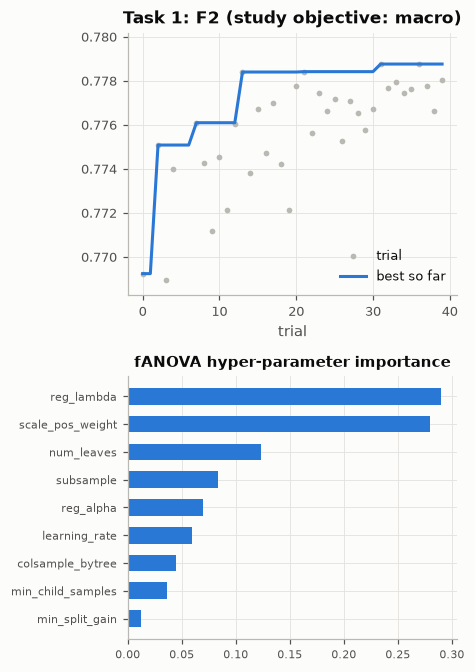

In [11]:
lgb_studies = [s for s in ("task1_lgb",) if studies.get(s) is not None]
fig, axes = plt.subplots(2, len(lgb_studies), figsize=(4.4 * len(lgb_studies), 6.2), squeeze=False)
labels = {"task1_lgb": "Task 1: F2 (study objective: macro)", "task2_lgb": "Task 2: macro-F1", "task3_lgb": "Task 3: NMAE"}
for j, s in enumerate(lgb_studies):
    df = studies[s].trials_dataframe().query("state == 'COMPLETE'")
    ax = axes[0, j]
    ax.scatter(df.number, df.value, s=14, color=MUTED, label="trial")
    ax.plot(df.number, df.value.cummax(), color=CAT[0], lw=2, label="best so far")
    ax.set_title(labels[s]); ax.set_xlabel("trial")
    lo = df.value.quantile(0.1); ax.set_ylim(lo - (df.value.max() - lo) * 0.1, df.value.max() + (df.value.max() - lo) * 0.15)
    imp = optuna.importance.get_param_importances(studies[s])
    imp = pd.Series(imp).sort_values()
    axes[1, j].barh(imp.index, imp.values, color=CAT[0], height=0.6)
    axes[1, j].set_title("fANOVA hyper-parameter importance", fontsize=10); axes[1, j].tick_params(labelsize=7.5)
axes[0, 0].legend(loc="lower right")
plt.tight_layout(); savefig(fig, "optuna"); plt.show()

In [12]:
def tuned(name, fallback):
    p = load_params(name)                                   # written when a study completes
    if p is None and studies.get(name) is not None and len(studies[name].trials):
        p = studies[name].best_params                       # partially-run study: best trial so far
    p = dict(fallback) if p is None else dict(p)
    if "learning_rate" in p:
        p["learning_rate"] = p["learning_rate"] / 2      # finer steps for the final fit
    return p


spw = (y1 == 0).sum() / (y1 == 1).sum()
P1_lgb = tuned("task1_lgb", {"learning_rate": 0.05, "scale_pos_weight": spw})
P1_cat = tuned("task1_cat", {"learning_rate": 0.06, "depth": 6, "scale_pos_weight": spw})
P1_xgb = {"learning_rate": 0.03, "max_depth": 6, "min_child_weight": 10, "subsample": 0.8, "colsample_bytree": 0.6, "scale_pos_weight": spw}
shown = [("P1_lgb", P1_lgb), ("P1_cat", P1_cat), ("P1_xgb", P1_xgb)]
for name, v in shown:
    print(f"{name}: {json.dumps({a: (round(b, 4) if isinstance(b, float) else b) for a, b in v.items()})}")

P1_lgb: {"learning_rate": 0.0156, "num_leaves": 34, "min_child_samples": 75, "colsample_bytree": 0.4314, "subsample": 0.969, "reg_alpha": 0.0099, "reg_lambda": 0.0029, "min_split_gain": 0.4812, "scale_pos_weight": 1.0143}
P1_cat: {"learning_rate": 0.03, "depth": 6, "scale_pos_weight": 1.8626}
P1_xgb: {"learning_rate": 0.03, "max_depth": 6, "min_child_weight": 10, "subsample": 0.8, "colsample_bytree": 0.6, "scale_pos_weight": 1.8626}


<a id="7"></a>
# 7. Stacking Ensemble (K-Fold) & Final Decision

**Level 1:** diverse model families trained on identical folds: three GBDTs with different tree-growth biases (LightGBM leaf-wise, XGBoost depth-wise, CatBoost oblivious trees), plus a bagged randomised-tree ensemble (ExtraTrees) and a linear model (logistic regression on Gaussian-rank features). Task 1 adds four members built the way last year's 1st-place team built theirs (CPE342 1/2025, public repo [Saltywan/CPE342-KAGGLE](https://github.com/Saltywan/CPE342-KAGGLE)): Random Forest, LightGBM, XGBoost and CatBoost on 24 of the 31 raw columns with training-median imputation, each averaged over two seeds. They see the data differently from our members, and adding them raises the nested OOF F2 by +0.0016 (95% CI [+0.0008, +0.0024], better in 5/5 folds, also better under test-like missingness).

**Level 2:** a regularised logistic-regression stacker on the level-1 OOF log-odds. The stacker is itself cross-validated **on the same folds**, so its reported score is also out-of-fold. Its test input is the fold-averaged level-1 test predictions.

**Post-processing:** the decision rule is tuned on stacked OOF predictions to maximise the *exact* metric:
* Task 1: threshold moving (Provost, 2000).

## 7.1 Task 1: Anti-cheat (F2)

In [13]:
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

make_et1 = lambda: ExtraTreesClassifier(n_estimators=400, min_samples_leaf=4, max_features=0.4, class_weight="balanced",
                                        n_jobs=-1, random_state=SEED)
make_lr1 = lambda: make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                 QuantileTransformer(output_distribution="normal", random_state=SEED),
                                 LogisticRegression(C=0.3, max_iter=3000, class_weight="balanced"))
m1 = {}
m1["LightGBM"] = cached("t1_lgb", lambda: run_cv("lgb", "binary", P1_lgb, X1, y1, X1_test, folds1, name="T1 lgb"))
m1["XGBoost"] = cached("t1_xgb", lambda: run_cv("xgb", "binary", P1_xgb, X1, y1, X1_test, folds1, name="T1 xgb"))
m1["CatBoost"] = cached("t1_cat", lambda: run_cv("cat", "binary", P1_cat, X1, y1, X1_test, folds1, name="T1 cat"))
m1["ExtraTrees"] = cached("t1_et", lambda: run_cv_sklearn(make_et1, "binary", X1.values, y1, X1_test.values, folds1, name="T1 et"))
m1["LogReg"] = cached("t1_lr", lambda: run_cv_sklearn(make_lr1, "binary", X1.values, y1, X1_test.values, folds1, name="T1 logreg"))

# Four more members built the way last year's 1st-place team built theirs (CPE342 1/2025, github.com/Saltywan/CPE342-KAGGLE):
# 24 of the 31 raw columns, training-median imputation, near-default settings, each averaged over two seeds. Their different
# inputs make them diverse: OOF F2 +0.0016 (95% CI [+0.0008, +0.0024], 5/5 folds), test-like +0.0023 (round 11, bn_/bo_ scripts).
R1, R1_test = task1.build_c24(t1_train, t1_test)
P24 = {"lgb": {"learning_rate": 0.05, "num_leaves": 31}, "xgb": {"learning_rate": 0.05, "max_depth": 6}, "cat": {"learning_rate": 0.08, "depth": 6}}
SEEDS24 = (42, 7)
seed_kw = lambda kind, s: {"random_seed": s} if kind == "cat" else {"random_state": s}
make_rf24 = lambda s: (lambda: RandomForestClassifier(n_estimators=300, max_depth=10, max_features=0.7, n_jobs=-1, random_state=s))
seed_avg = lambda rs: {k: np.mean([r[k] for r in rs], axis=0) for k in ("oof", "test")}
m1["RF-24"] = cached("t1_rf24", lambda: seed_avg([run_cv_sklearn(make_rf24(s), "binary", R1.values, y1, R1_test.values, folds1,
                                                                 name=f"T1 rf24 seed {s}") for s in SEEDS24]))
for kind, nm in (("lgb", "LightGBM-24"), ("xgb", "XGBoost-24"), ("cat", "CatBoost-24")):
    m1[nm] = cached(f"t1_{kind}24", lambda kind=kind: seed_avg([run_cv(kind, "binary", {**P24[kind], **seed_kw(kind, s)}, R1, y1, R1_test,
                                                                      folds1, name=f"T1 {kind}24 seed {s}") for s in SEEDS24]))

def stack_binary(models, y, folds, C_=1.0):
    S = np.column_stack([logit(m["oof"]) for m in models.values()])
    St = np.column_stack([logit(m["test"]) for m in models.values()])
    oof = np.zeros(len(y))
    for tr, va in folds:
        oof[va] = LogisticRegression(C=C_, max_iter=2000).fit(S[tr], y[tr]).predict_proba(S[va])[:, 1]
    final = LogisticRegression(C=C_, max_iter=2000).fit(S, y)
    return oof, final.predict_proba(St)[:, 1], final.coef_.ravel(), final

stack1_oof, stack1_test, coef1, STACKER1 = stack_binary(m1, y1, folds1)
avg1_oof = np.mean([m["oof"] for m in m1.values()], axis=0)
rows = []
for name, p in [*[(k, v["oof"]) for k, v in m1.items()], ("Mean of probabilities", avg1_oof), ("LogReg stacker (OOF)", stack1_oof)]:
    thr, s = optimize_threshold(y1, p, 2.0)
    thr_b, s_b = optimize_threshold(y1, p, 2.0, average="binary")
    rows.append([name, roc_auc_score(y1, p), s, thr, s_b, thr_b])
t1_table = pd.DataFrame(rows, columns=["model", "AUC", "macro-F2", "thr (macro)", "binary-F2", "thr (binary)"]).set_index("model")
display(t1_table.style.format("{:.4f}").highlight_max(subset=["AUC", "macro-F2", "binary-F2"], props="font-weight:bold"))
print("stacker log-odds weights:", dict(zip(m1, np.round(coef1, 3))))

,AUC,macro-F2,thr (macro),binary-F2,thr (binary)
model,,,,,
LightGBM,0.8902,0.8362,0.1822,0.8362,0.1822
XGBoost,0.8871,0.8353,0.2000,0.8353,0.2000
CatBoost,0.8891,0.8358,0.2401,0.8358,0.2401
ExtraTrees,0.8524,0.8109,0.2904,0.8109,0.2904
LogReg,0.7623,0.7575,0.2353,0.7575,0.2353
RF-24,0.8391,0.8188,0.1750,0.8188,0.1750
LightGBM-24,0.8905,0.8360,0.1857,0.8360,0.1857
XGBoost-24,0.8897,0.8353,0.1741,0.8353,0.1741
CatBoost-24,0.8910,0.8371,0.1752,0.8371,0.1752


stacker log-odds weights: {'LightGBM': np.float64(0.241), 'XGBoost': np.float64(-0.009), 'CatBoost': np.float64(0.248), 'ExtraTrees': np.float64(-0.276), 'LogReg': np.float64(-0.033), 'RF-24': np.float64(0.128), 'LightGBM-24': np.float64(0.065), 'XGBoost-24': np.float64(0.151), 'CatBoost-24': np.float64(0.558)}


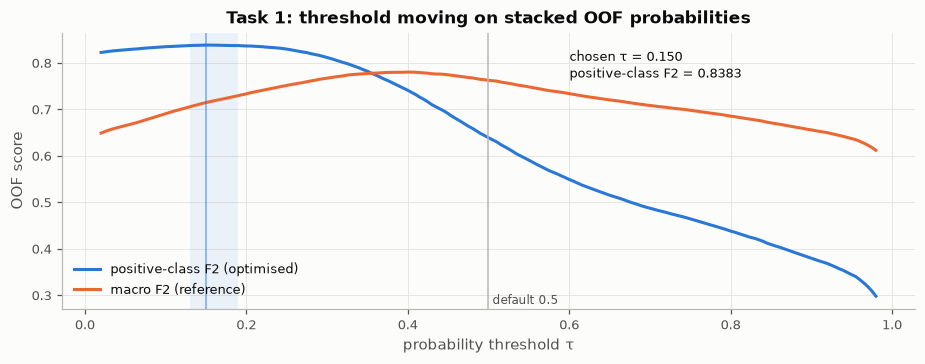

OOF positive-class F2 at the default 0.5: 0.6387 -> best 0.8383 at τ=0.150
one-SE plateau (SE = 0.0013): τ in [0.130, 0.190] -> chosen τ=0.150 (the OOF optimum), positive-class F2 0.8383
regret check: at τ=0.150 the other reading (macro) scores 0.7147 vs 0.7801 at its own optimum τ=0.400
test flagged as cheaters: 60.71% (train prevalence 34.93%)


In [14]:
THR1_opt, SCORE1_opt = optimize_threshold(y1, stack1_oof, 2.0)
OTHER_AVG = "macro" if FBETA_AVERAGE == "binary" else "binary"
THR1_alt, _ = optimize_threshold(y1, stack1_oof, 2.0, average=OTHER_AVG)
grid, curve_main = threshold_curve(y1, stack1_oof, 2.0, FBETA_AVERAGE)
_, curve_alt = threshold_curve(y1, stack1_oof, 2.0, OTHER_AVG)
# One-standard-error band (Breiman et al., 1984): thresholds whose OOF F2 lies within one bootstrap SE of the
# optimum are statistically tied, so the exact choice inside the band matters little. The slides define the
# positive-class F2, so we keep its OOF optimum. (v4 tried the band's macro-friendly end, 0.190, as a hedge
# for the macro reading; that submission scored lower, see the README leaderboard log.)
rng1 = np.random.default_rng(SEED)
pred_opt1 = (stack1_oof >= THR1_opt).astype(int)
SE1 = np.std([f2(y1[i], pred_opt1[i]) for i in (rng1.integers(0, len(y1), len(y1)) for _ in range(200))])
tied1 = curve_main >= SCORE1_opt - SE1
THR1, SCORE1 = THR1_opt, SCORE1_opt
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.axvspan(grid[tied1].min(), grid[tied1].max(), color=CAT[0], alpha=0.08, lw=0)
ax.plot(grid, curve_main, color=CAT[0], label=f"{AVG_NAME} F2 (optimised)")
ax.plot(grid, curve_alt, color=CAT[1], label=f"{'macro' if OTHER_AVG == 'macro' else 'positive-class'} F2 (reference)")
ax.axvline(THR1, color=CAT[0], lw=1, alpha=0.6); ax.axvline(0.5, color=MUTED, lw=1)
ax.annotate(f"chosen τ = {THR1:.3f}\n{AVG_NAME} F2 = {SCORE1:.4f}", (THR1, SCORE1), xytext=(THR1 + 0.45, SCORE1 - 0.07), fontsize=8.5,
            arrowprops=dict(arrowstyle="-", color=MUTED))
ax.text(0.505, ax.get_ylim()[0] + 0.01, "default 0.5", color="#52514e", fontsize=8)
ax.set_xlabel("probability threshold τ"); ax.set_ylabel("OOF score"); ax.set_title("Task 1: threshold moving on stacked OOF probabilities")
ax.legend(loc="lower left"); plt.tight_layout(); savefig(fig, "t1_threshold"); plt.show()
pred1 = (stack1_test >= THR1).astype(int)
print(f"OOF {AVG_NAME} F2 at the default 0.5: {f2(y1, (stack1_oof >= 0.5).astype(int)):.4f} -> best {SCORE1_opt:.4f} at τ={THR1_opt:.3f}")
print(f"one-SE plateau (SE = {SE1:.4f}): τ in [{grid[tied1].min():.3f}, {grid[tied1].max():.3f}] -> chosen τ={THR1:.3f} (the OOF optimum), {AVG_NAME} F2 {SCORE1:.4f}")
print(f"regret check: at τ={THR1:.3f} the other reading ({OTHER_AVG}) scores {fbeta(y1, (stack1_oof >= THR1).astype(int), 2, OTHER_AVG):.4f} "
      f"vs {fbeta(y1, (stack1_oof >= THR1_alt).astype(int), 2, OTHER_AVG):.4f} at its own optimum τ={THR1_alt:.3f}")
print(f"test flagged as cheaters: {pred1.mean():.2%} (train prevalence {y1.mean():.2%})")
summary.append(["Task 1", f"{AVG_NAME} F2", SCORE1, "5 L1 models -> LogReg stacker -> tuned threshold"])

## 7.6 Final model: combine Train+Val (competition rule)
The rules say: *"Combine Train+Val for training"* and *"✅ Allowed: combining Train and Validation sets for final model training after all validation is complete."* Everything above was validation: the 5-fold OOF predictions are what we scored, tuned and stacked on. Each fold model saw only 80% of the labelled data. Now, with every decision fixed, each level-1 model is **retrained once on 100% of the labelled rows**:

* **GBDTs:** the validated hyper-parameters are reused. The number of boosting rounds comes from early stopping on fold 0, ×1.15 for the 25% larger training set, so no hold-out is needed.
* **ExtraTrees / logistic regression / hurdle stages:** refitted on all rows.

The final level-1 test input is the **average of the 5-fold models and the full-data model**. Both are legitimate final models, and averaging them lowers variance. **Nothing is re-tuned:** the stacker, the threshold τ, the class multipliers, the L1 blend weights, the zero gate and the scale all keep their out-of-fold values. Task 5 has no labelled data, so its detectors are already fitted on all available data.

In [15]:
from src.modeling import refit_full, refit_full_sklearn
FULL_W = 0.5                                     # weight of the full-data model in the final test input
blend_full = lambda fold_test, full_test: (1 - FULL_W) * np.asarray(fold_test) + FULL_W * np.asarray(full_test)
changes = []

# ---- Task 1
f1 = {}
f1["LightGBM"] = cached("t1_lgb_full", lambda: refit_full("lgb", "binary", P1_lgb, X1, y1, X1_test, folds1, name="T1 lgb"))
f1["XGBoost"] = cached("t1_xgb_full", lambda: refit_full("xgb", "binary", P1_xgb, X1, y1, X1_test, folds1, name="T1 xgb"))
f1["CatBoost"] = cached("t1_cat_full", lambda: refit_full("cat", "binary", P1_cat, X1, y1, X1_test, folds1, name="T1 cat"))
f1["ExtraTrees"] = cached("t1_et_full", lambda: refit_full_sklearn(make_et1, "binary", X1.values, y1, X1_test.values))
f1["LogReg"] = cached("t1_lr_full", lambda: refit_full_sklearn(make_lr1, "binary", X1.values, y1, X1_test.values))
f1["RF-24"] = cached("t1_rf24_full", lambda: {"test": np.mean([refit_full_sklearn(make_rf24(s), "binary", R1.values, y1, R1_test.values)["test"]
                                                               for s in SEEDS24], axis=0)})
for kind, nm in (("lgb", "LightGBM-24"), ("xgb", "XGBoost-24"), ("cat", "CatBoost-24")):
    f1[nm] = cached(f"t1_{kind}24_full", lambda kind=kind: {"test": np.mean([refit_full(kind, "binary", {**P24[kind], **seed_kw(kind, s)}, R1, y1,
                                                                                         R1_test, folds1, name=f"T1 {kind}24 seed {s}")["test"]
                                                                              for s in SEEDS24], axis=0)})
St1 = np.column_stack([logit(blend_full(m1[k]["test"], f1[k]["test"])) for k in m1])
stack1_test_final = STACKER1.predict_proba(St1)[:, 1]
pred1_final = (stack1_test_final >= THR1).astype(int)
changes.append(["Task 1", "labels changed", np.mean(pred1_final != pred1), f"flag rate {pred1.mean():.2%} -> {pred1_final.mean():.2%}"])

display(pd.DataFrame(changes, columns=["task", "check", "value", "note"]).set_index("task").round(4))
pred1 = pred1_final   # used by section 9

,check,value,note
task,,,
Task 1,labels changed,0.0042,flag rate 60.71% -> 60.60%


<a id="8"></a>
# 8. Feature Importance Analysis

Exact **TreeSHAP** (Lundberg & Lee) values come from a LightGBM model refit on fold 0 with the tuned parameters, explaining 4,000 held-out rows, complemented by model-agnostic **permutation importance** (the metric drop when a column is shuffled on the held-out fold).

In [16]:
import lightgbm as lgb
from sklearn.inspection import permutation_importance

def fold0_lgb(params, X, y, objective, n_classes=None):
    tr, va = (folds1 if objective == "binary" else folds2 if objective == "multiclass" else folds3)[0]
    from src.modeling import LGB_BASE
    p = {**LGB_BASE, **params, "objective": {"binary": "binary", "multiclass": "multiclass", "regression": "regression_l1"}[objective]}
    Model = lgb.LGBMRegressor if objective == "regression" else lgb.LGBMClassifier
    m = Model(**p).fit(X.iloc[tr], y[tr], eval_set=[(X.iloc[va], y[va])], callbacks=[lgb.early_stopping(200, verbose=False)])
    return m, va

def tree_shap(model, Xs):
    # LightGBM's built-in TreeSHAP (pred_contrib) - exact, handles categoricals; drops the bias column
    c = model.booster_.predict(Xs, pred_contrib=True, num_iteration=model.best_iteration_)
    k = Xs.shape[1] + 1
    return c.reshape(len(Xs), -1, k)[:, :, :-1] if c.shape[1] > k else c[:, :-1]

def shap_panel(ax, sv, Xs, title, top=14):
    imp = pd.Series(np.abs(sv).mean(0), index=Xs.columns).sort_values().tail(top)
    ax.barh(imp.index, imp.values, color=CAT[0], height=0.65)
    ax.set_title(title); ax.set_xlabel("mean |SHAP|"); ax.tick_params(axis="y", labelsize=8)
    return imp

def dependence(ax, sv, Xs, col, color=CAT[0]):
    j = list(Xs.columns).index(col)
    x = Xs[col].values
    lo, hi = np.nanpercentile(x, [0.5, 99.5])
    m = ~np.isnan(x) & (x >= lo) & (x <= hi)
    ax.scatter(x[m], sv[m, j], s=3, alpha=0.35, color=color, rasterized=True)
    ax.axhline(0, color=MUTED, lw=0.8); ax.set_xlabel(col); ax.set_ylabel("SHAP value")

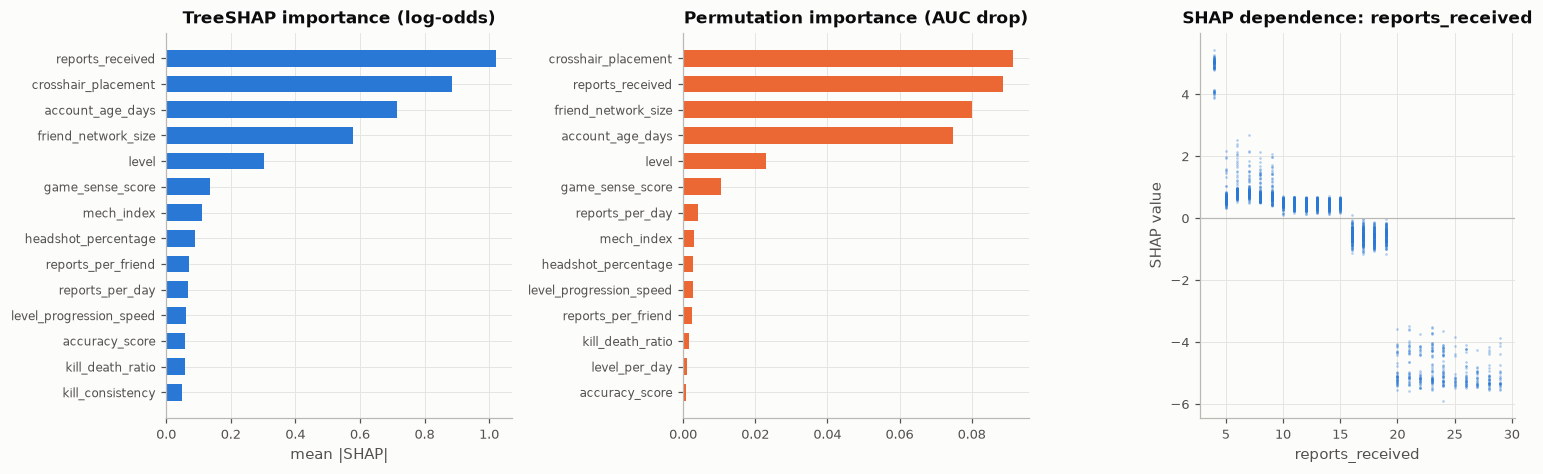

In [17]:
mdl1, va1 = fold0_lgb(P1_lgb, X1, y1, "binary")
Xs1 = X1.iloc[va1].sample(4000, random_state=SEED)
sv1 = tree_shap(mdl1, Xs1)
pi1 = permutation_importance(mdl1, X1.iloc[va1], y1[va1], scoring="roc_auc", n_repeats=3, random_state=SEED, n_jobs=1)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.1, 1.1, 1]})
imp1 = shap_panel(axes[0], sv1, Xs1, "TreeSHAP importance (log-odds)")
pim = pd.Series(pi1.importances_mean, index=X1.columns).sort_values().tail(14)
axes[1].barh(pim.index, pim.values, color=CAT[1], height=0.65); axes[1].set_title("Permutation importance (AUC drop)")
axes[1].tick_params(axis="y", labelsize=8)
dependence(axes[2], sv1, Xs1, imp1.index[-1]); axes[2].set_title(f"SHAP dependence: {imp1.index[-1]}")
plt.tight_layout(); savefig(fig, "t1_shap"); plt.show()

**Business reading (anti-cheat).** Five account-context signals carry the model: `reports_received`, `crosshair_placement`, `account_age_days`, `friend_network_size` and `level`. Both TreeSHAP and permutation importance agree on them. Engineered mechanical ratios add little on top. The SHAP dependence plot shows a **step function**:
* exactly 4 reports gives about +5 log-odds, and only cheaters have it;
* 5–15 reports gives a mild push towards cheating;
* **20 or more reports gives about −5 log-odds, and such accounts are always legitimate.**

In this data the most-reported players are **innocent targets of frustrated opponents**. That is exactly why Karena's current report-driven system has a 70% false-positive rate. Practical consequences:
* **Stop ranking the review queue by report count.** Rank it by model probability. At the tuned threshold the pre-filter keeps recall high, as $F_2$ demands, so few real cheaters slip past the 500-cases-per-day bottleneck.
* **Auto-clear mass-reported veterans.** Accounts with 20+ reports, long tenure and large friend networks can be deprioritised, which protects legitimate high-skill players from wrongful bans.
* **Show each case's top SHAP drivers** to reviewers, so a 10-minute manual review becomes a quick confirmation.

<a id="9"></a>
# 9. Submission

The Task 1 column of the submission: `task1` is a plain integer code, as defined in the datacard. The part is written to `outputs/submission_parts/task1.csv` with the `id` column of `sample_submission.csv`; `python scripts/make_submission.py` checks and joins the five parts.

In [18]:
sample_sub = pd.read_csv(C.SAMPLE_SUB)
part = pd.DataFrame({"id": sample_sub.id, "task1": pred1.astype(int)})
assert len(part) == C.N_TEST == len(t1_test) and part.id.tolist() == [f"ANS{i:05d}" for i in range(1, C.N_TEST + 1)]
assert part["task1"].notna().all() and set(part.task1.unique()) <= {0, 1}
part_dir = C.OUT / "submission_parts"
part_dir.mkdir(exist_ok=True)
part.to_csv(part_dir / "task1.csv", index=False)
print(f"saved {part_dir / 'task1.csv'} | {part.shape}")
display(part.head())
print(f"flagged as cheaters: {part.task1.mean():.2%} (train prevalence {y1.mean():.2%}) at τ={THR1:.3f}")

saved C:\Users\Oping\cpe342-kaggle-main\outputs\submission_parts\task1.csv | (25889, 2)


,id,task1
0,ANS00001,1
1,ANS00002,1
2,ANS00003,1
3,ANS00004,1
4,ANS00005,0


flagged as cheaters: 60.60% (train prevalence 34.93%) at τ=0.150


<a id="10"></a>
# 10. Conclusion

In [19]:
display(pd.DataFrame(summary, columns=["task", "metric", "OOF score", "final recipe"]).set_index("task").style.format({"OOF score": "{:.4f}"}))

,metric,OOF score,final recipe
task,,,
Task 1,positive-class F2,0.8383,5 L1 models -> LogReg stacker -> tuned threshold


| Task | Key insight | What moved the score |
|---|---|---|
| 1 Anti-cheat | Noisy additive signal; recall-weighted metric; test rows have fewer missing values | Cost-sensitive GBDTs (`scale_pos_weight` tuned) → 5-model stack → **threshold moving** on OOF (optimum inside a flat one-SE band) |